# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


**Fallback** — это запасной режим. Его используют, когда основной вариант не получается запустить: нет GPU, не хватает видеопамяти, обучение идёт слишком долго или модель не загружается.

## Реализация


In [16]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в том числе одноимённый test_metrics.json.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab2"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data'}


In [17]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Задание 1. Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Сегментатор** — это модель для семантической сегментации. Она присваивает класс каждому пикселю изображения, а не всей картинке целиком.

In [10]:
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms as T
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import InterpolationMode

IMG_SIZE = 128 if FAST_DEV_RUN else 256
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# Изображение и маска приводятся к одному размеру IMG_SIZE x IMG_SIZE.
# Изображение — билинейно, маска — только NEAREST: метки классов нельзя усреднять.
img_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
mask_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.NEAREST),
    T.PILToTensor(),  # uint8 [1, H, W] с исходными метками 1..3, без деления на 255
])


class SyntheticPets(Dataset):
    """Smoke-замена Oxford-IIIT Pet: эллипс-«питомец» с тем же trimap (1 — объект, 2 — фон, 3 — граница)."""

    def __init__(self, n, transform=None, target_transform=None, seed=SEED):
        self.n, self.transform, self.target_transform, self.seed = n, transform, target_transform, seed

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        rng = np.random.default_rng(self.seed + i)
        h, w = (int(v) for v in rng.integers(160, 320, 2))
        yy, xx = np.mgrid[:h, :w]
        cy, cx = h * rng.uniform(0.35, 0.65), w * rng.uniform(0.35, 0.65)
        ry, rx = h * rng.uniform(0.15, 0.35), w * rng.uniform(0.15, 0.35)
        d = ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2
        mask = np.full((h, w), 2, dtype=np.uint8)
        mask[d < 1.15] = 3
        mask[d < 0.85] = 1
        img = rng.integers(0, 60, (h, w, 3)).astype(np.uint8)
        img[mask == 1] += rng.integers(80, 190, 3).astype(np.uint8)
        img, mask = Image.fromarray(img), Image.fromarray(mask)
        if self.transform is not None:
            img = self.transform(img)
        if self.target_transform is not None:
            mask = self.target_transform(mask)
        return img, mask


def make_ds(split, transform=None, target_transform=None):
    """Раздел Oxford-IIIT Pet с масками; в FAST_DEV_RUN — синтетический датасет того же формата."""
    if FAST_DEV_RUN:
        return SyntheticPets(64, transform, target_transform, seed=SEED + (0 if split == "trainval" else 10_000))
    return OxfordIIITPet(root=str(DATA_ROOT), split=split, target_types="segmentation",
                         transform=transform, target_transform=target_transform, download=True)


ds = make_ds("trainval", img_tf, mask_tf)
raw_ds = make_ds("trainval")  # те же пары без преобразований — для проверки интерполяции

x, m = ds[0]
print({"len": len(ds), "image": tuple(x.shape), "mask": tuple(m.shape), "mask_dtype": str(m.dtype)})
check(x.shape[-2:] == m.shape[-2:] == (IMG_SIZE, IMG_SIZE), "изображение и маска масштабированы до одного размера")

# Проверка интерполяции: после NEAREST в маске остаются только исходные метки,
# а доли классов почти не меняются. Билинейная интерполяция для сравнения
# подменяет метки на стыке 1 (объект) и 3 (граница) ложным классом 2 (фон).
bilinear_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR), T.PILToTensor()])
n_check = min(len(ds), 16 if FAST_DEV_RUN else 200)
seen, max_shift, changed = set(), 0.0, 0.0
for i in range(n_check):
    raw_mask = raw_ds[i][1]
    src = torch.from_numpy(np.array(raw_mask))
    near, bil = mask_tf(raw_mask), bilinear_tf(raw_mask)
    seen |= set(near.unique().tolist())
    shares = lambda t: torch.stack([(t == c).float().mean() for c in (1, 2, 3)])
    max_shift = max(max_shift, (shares(src) - shares(near)).abs().max().item())
    changed += (near != bil).float().mean().item() / n_check

print({"classes_after_resize": sorted(seen), "max_class_share_shift": round(max_shift, 4),
       "bilinear_changed_pixels": round(changed, 4)})
check(seen <= {1, 2, 3}, "NEAREST сохраняет исходные метки классов 1..3")
check(max_shift < 0.02, "доли классов после масштабирования маски практически не меняются")


{'len': 3680, 'image': (3, 256, 256), 'mask': (1, 256, 256), 'mask_dtype': 'torch.uint8'}
✔ изображение и маска масштабированы до одного размера
{'classes_after_resize': [1, 2, 3], 'max_class_share_shift': 0.0019, 'bilinear_changed_pixels': 0.0064}
✔ NEAREST сохраняет исходные метки классов 1..3
✔ доли классов после масштабирования маски практически не меняются


### Задание 2. Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
from torch.utils.data import DataLoader, Subset

VAL_FRACTION = 0.15
BATCH_SIZE = 8 if FAST_DEV_RUN else 32
NUM_CLASSES = 3

# Разделение по индексам изображений с фиксированным seed: каждое изображение попадает ровно в одну часть.
perm = torch.randperm(len(ds), generator=torch.Generator().manual_seed(SEED)).tolist()
n_val = max(1, int(len(ds) * VAL_FRACTION))
val_idx, train_idx = sorted(perm[:n_val]), sorted(perm[n_val:])
train_ds, val_ds = Subset(ds, train_idx), Subset(ds, val_idx)


def normalize_mask(mask):
    """Trimap Oxford-IIIT Pet 1..3 -> индексы классов 0..2 (0 — объект, 1 — фон, 2 — граница), long без канала."""
    mask = mask.long() - 1
    return mask.squeeze(-3) if mask.dim() >= 3 and mask.shape[-3] == 1 else mask


def collate(batch):
    """Собирает батч: изображения [B, 3, H, W] float и уже перекодированные маски [B, H, W] long."""
    images, masks = zip(*batch)
    return torch.stack(images), normalize_mask(torch.stack(masks))


# num_workers=0: функции и классы, объявленные в notebook, не передаются в процессы-воркеры на Windows.
loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, collate_fn=collate,
                    num_workers=0, pin_memory=DEVICE == "cuda", generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate,
                        num_workers=0, pin_memory=DEVICE == "cuda")

xb, yb = next(iter(loader))
print({"train": len(train_ds), "val": len(val_ds), "batches": len(loader), "val_batches": len(val_loader),
       "x": tuple(xb.shape), "y": tuple(yb.shape), "y_dtype": str(yb.dtype), "y_classes": yb.unique().tolist()})
check(not set(train_idx) & set(val_idx), "индексы train и validation не пересекаются")
check(len(train_idx) + len(val_idx) == len(ds), "train и validation вместе покрывают весь trainval")
check(yb.dtype == torch.long and set(yb.unique().tolist()) <= set(range(NUM_CLASSES)), "метки перекодированы в 0..2 типа long")
check(yb.shape == (xb.shape[0], *xb.shape[-2:]), "маска батча имеет форму [B, H, W], согласованную с изображениями")


{'train': 3128, 'val': 552, 'batches': 97, 'val_batches': 18, 'x': (32, 3, 256, 256), 'y': (32, 256, 256), 'y_dtype': 'torch.int64', 'y_classes': [0, 1, 2]}
✔ индексы train и validation не пересекаются
✔ train и validation вместе покрывают весь trainval
✔ метки перекодированы в 0..2 типа long
✔ маска батча имеет форму [B, H, W], согласованную с изображениями


### Задание 3. Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**IoU** (Intersection over Union) — это метрика, которая показывает, насколько предсказанная маска совпадает с истинной. По-русски её называют «пересечение над объединением».

In [ ]:
from torch import nn
from torchvision.models.segmentation import LRASPP_MobileNet_V3_Large_Weights, lraspp_mobilenet_v3_large


def make_model(num_classes=NUM_CLASSES):
    """LRASPP-MobileNetV3 с предобученными весами и новыми головами на num_classes классов."""
    if FAST_DEV_RUN:  # smoke-режим: без скачивания весов
        net = lraspp_mobilenet_v3_large(weights=None, weights_backbone=None)
    else:
        net = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.DEFAULT)
    # У LRASPP две классификационные головы 1x1: по низко- и высокоуровневым признакам; их логиты складываются.
    head = net.classifier
    head.low_classifier = nn.Conv2d(head.low_classifier.in_channels, num_classes, kernel_size=1)
    head.high_classifier = nn.Conv2d(head.high_classifier.in_channels, num_classes, kernel_size=1)
    return net.to(DEVICE)


def mean_iou(pred, target, num_classes=NUM_CLASSES):
    """Средний по классам IoU = |P_c ∩ G_c| / |P_c ∪ G_c|.

    pred — логиты [B, C, H, W] или метки [B, H, W]; target — метки [B, H, W].
    Классы, которых нет ни в предсказании, ни в разметке, в среднее не входят.
    """
    if pred.dim() == target.dim() + 1:
        pred = pred.argmax(dim=1)
    ious = []
    for c in range(num_classes):
        p, g = pred == c, target == c
        union = (p | g).sum().item()
        if union > 0:
            ious.append((p & g).sum().item() / union)
    return float(np.mean(ious)) if ious else float("nan")


torch.manual_seed(SEED)
model = make_model()

model.eval()
with torch.no_grad():
    logits = model(xb.to(DEVICE))["out"]
print({"logits": tuple(logits.shape), "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
       "mIoU_before_training": round(mean_iou(logits.cpu(), yb), 4)})
check(logits.shape == (xb.shape[0], NUM_CLASSES, *xb.shape[-2:]), "модель выдаёт логиты [B, 3, H, W] в разрешении входа")
check(mean_iou(yb, yb) == 1.0, "IoU маски с самой собой равен 1")
_p, _g = torch.tensor([[0, 0, 1, 1]]), torch.tensor([[0, 1, 1, 1]])  # класс 0: 1/2, класс 1: 2/3, класса 2 нет
check(abs(mean_iou(_p, _g) - (1 / 2 + 2 / 3) / 2) < 1e-9, "IoU на ручном примере совпадает с расчётом по пересечению и объединению")


{'logits': (32, 3, 256, 256), 'params_M': 3.22, 'mIoU_before_training': 0.1947}
✔ модель выдаёт логиты [B, 3, H, W] в разрешении входа
✔ IoU маски с самой собой равен 1
✔ IoU на ручном примере совпадает с расчётом по пересечению и объединению


### Задание 4. Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Кросс-энтропия (cross-entropy) — это функция потерь для классификации. Она «штрафует» модель тем сильнее, чем меньшую вероятность модель дала правильному классу.

In [13]:
EPOCHS = 1 if FAST_DEV_RUN else 6
LR, WEIGHT_DECAY = 5e-4, 1e-4
USE_AMP = DEVICE == "cuda"  # mixed precision только на GPU
TRAIN_CONFIG = {"epochs": EPOCHS, "lr": LR, "weight_decay": WEIGHT_DECAY, "img_size": IMG_SIZE,
                "batch_size": BATCH_SIZE, "fast_dev_run": FAST_DEV_RUN, "seed": SEED}
criterion = nn.CrossEntropyLoss()  # логиты [B, C, H, W] против меток [B, H, W]: усреднение по всем пикселям


def train_one_epoch(model, loader, optimizer, scaler, augment=None):
    """Одна эпоха: cross-entropy по пикселям, обратное распространение и шаг AdamW. Возвращает средний loss."""
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        if augment is not None:
            x, y = augment(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            loss = criterion(model(x)["out"], y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * x.shape[0]
        n += x.shape[0]
    return total / n


def fit(model, loader, state_path, epochs=EPOCHS, augment=None):
    """Обучает модель epochs эпох; после каждой эпохи сохраняет состояние и продолжает с него после перезапуска."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)
    history = []
    if state_path.exists():
        state = torch.load(state_path, map_location=DEVICE)
        if state["config"] == TRAIN_CONFIG:  # состояние от другой конфигурации не продолжаем
            model.load_state_dict(state["model"])
            optimizer.load_state_dict(state["optimizer"])
            scaler.load_state_dict(state["scaler"])
            history = state["history"]
            print(f"продолжение с эпохи {len(history) + 1} ({state_path.name})")
    for epoch in range(len(history), epochs):
        t0 = time.time()
        history.append(train_one_epoch(model, loader, optimizer, scaler, augment))
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "config": TRAIN_CONFIG}, state_path)
        print(f"эпоха {epoch + 1}/{epochs}: loss={history[-1]:.4f}, {time.time() - t0:.0f} с")
    return history


history = fit(model, loader, ARTIFACTS / "train_state.pt")
print({"history": [round(v, 4) for v in history]})
check(len(history) == EPOCHS and all(np.isfinite(history)), "history содержит конечный loss за каждую эпоху")
check(len(history) < 2 or history[-1] < history[0], "loss на train снизился за время обучения")


эпоха 1/6: loss=0.2995, 55 с
эпоха 2/6: loss=0.2007, 22 с
эпоха 3/6: loss=0.1759, 22 с
эпоха 4/6: loss=0.1615, 22 с
эпоха 5/6: loss=0.1529, 22 с
эпоха 6/6: loss=0.1413, 22 с
{'history': [0.2995, 0.2007, 0.1759, 0.1615, 0.1529, 0.1413]}
✔ history содержит конечный loss за каждую эпоху
✔ loss на train снизился за время обучения


### Задание 5. Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Накопленная confusion matrix по validation** — таблица «истинный класс × предсказанный класс», в которую по **всем батчам** validation складывается каждый пиксель (+1 в клетку [истина, предсказание]). Validation используется один раз — после обучения; во время обучения считался только train loss.

| истина \ предсказание | pet | background | border |
|---|---|---|---|
| **pet** | **TP** | FN | FN |
| **background** | FP | | |
| **border** | FP | | |

*(разметка TP/FP/FN — для класса pet)*: TP — диагональ, FN — остальное в строке (пропустили), FP — остальное в столбце (лишнее).

**IoU (пересечение над объединением)** для класса: $IoU = \dfrac{|P \cap G|}{|P \cup G|} = \dfrac{TP}{TP + FP + FN}$, от 0 до 1.

**mIoU** — *mean* (среднее, не min) IoU по трём классам: $mIoU = \dfrac{IoU_{pet} + IoU_{bg} + IoU_{border}}{3}$.

In [14]:
CLASS_NAMES = ["pet", "background", "border"]  # индексы 0..2 после normalize_mask


@torch.no_grad()
def confusion_matrix(model, loader, num_classes=NUM_CLASSES):
    """Матрица ошибок по пикселям всего загрузчика: строки — истинный класс, столбцы — предсказанный."""
    model.eval()
    cm = torch.zeros(num_classes, num_classes, dtype=torch.long, device=DEVICE)
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            pred = model(x)["out"].argmax(dim=1)
        cm += torch.bincount((y * num_classes + pred).flatten(), minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return cm.cpu()


def iou_from_confusion(cm):
    """IoU_c = TP_c / (TP_c + FP_c + FN_c): диагональ, делённая на (сумма строки + сумма столбца − диагональ)."""
    tp = cm.diag().double()
    union = cm.sum(dim=0).double() + cm.sum(dim=1).double() - tp
    return (tp / union.clamp(min=1)).tolist()


def evaluate(model, loader):
    """Метрики сегментации по накопленной матрице ошибок."""
    cm = confusion_matrix(model, loader)
    ious = iou_from_confusion(cm)
    return {"miou": float(np.mean(ious)), "iou_per_class": dict(zip(CLASS_NAMES, ious)),
            "pixel_accuracy": cm.diag().sum().item() / cm.sum().item(), "confusion_matrix": cm.tolist()}


val_metrics = evaluate(model, val_loader)
torch.save(model.state_dict(), ARTIFACTS / "segmentation.pt")
(ARTIFACTS / "val_metrics.json").write_text(json.dumps(
    {**val_metrics, "n_images": len(val_ds), "train_loss_history": history, "config": TRAIN_CONFIG},
    ensure_ascii=False, indent=2), encoding="utf-8")

print({"val_mIoU": round(val_metrics["miou"], 4), "pixel_accuracy": round(val_metrics["pixel_accuracy"], 4),
       "iou_per_class": {k: round(v, 4) for k, v in val_metrics["iou_per_class"].items()}})
check(sum(map(sum, val_metrics["confusion_matrix"])) == len(val_ds) * IMG_SIZE ** 2, "матрица ошибок учитывает каждый пиксель validation ровно один раз")
check((ARTIFACTS / "segmentation.pt").exists() and (ARTIFACTS / "val_metrics.json").exists(), "segmentation.pt и val_metrics.json сохранены")


{'val_mIoU': 0.7835, 'pixel_accuracy': 0.9285, 'iou_per_class': {'pet': 0.8776, 'background': 0.9379, 'border': 0.5349}}
✔ матрица ошибок учитывает каждый пиксель validation ровно один раз
✔ segmentation.pt и val_metrics.json сохранены


### Задание 6. Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Горизонтальное отражение - это аугментация: картинку зеркально переворачивают слева направо. Например, кот, смотревший влево, теперь смотрит вправо.<br>
«Синхронное» значит, что изображение и его маску отражают одновременно и одинаково.

In [15]:
def sync_hflip(x, y, p=0.5):
    """Синхронное горизонтальное отражение батча: одно и то же решение на изображение [B, 3, H, W] и его маску [B, H, W]."""
    flip = torch.rand(x.shape[0], device=x.device) < p
    x = torch.where(flip[:, None, None, None], x.flip(-1), x)
    y = torch.where(flip[:, None, None], y.flip(-1), y)
    return x, y


_xf, _yf = sync_hflip(xb, yb, p=1.0)
check(torch.equal(_xf, xb.flip(-1)) and torch.equal(_yf, yb.flip(-1)), "при p=1 изображение и маска отражены по одной и той же оси")
_x0, _y0 = sync_hflip(xb, yb, p=0.0)
check(torch.equal(_x0, xb) and torch.equal(_y0, yb), "при p=0 пара остаётся без изменений")
torch.manual_seed(SEED)
_xr, _yr = sync_hflip(xb, yb)
_flipped_x = torch.tensor([not torch.equal(a, b) for a, b in zip(_xr, xb)])
_flipped_y = torch.tensor([not torch.equal(a, b) for a, b in zip(_yr, yb)])
check(torch.equal(_flipped_x, _flipped_y), "в случайном режиме отражаются одни и те же элементы батча в изображениях и масках")

# Тот же бюджет, что у исходной модели: те же данные, инициализация, число эпох и гиперпараметры (TRAIN_CONFIG);
# единственное отличие — отражение с вероятностью 0.5 на обучении. Validation не аугментируется.
torch.manual_seed(SEED)
model_aug = make_model()
history_aug = fit(model_aug, loader, ARTIFACTS / "train_state_aug.pt", augment=sync_hflip)
val_metrics_aug = evaluate(model_aug, val_loader)
torch.save(model_aug.state_dict(), ARTIFACTS / "segmentation_aug.pt")

augmentation_comparison = {
    "baseline": {"val_miou": val_metrics["miou"], "iou_per_class": val_metrics["iou_per_class"], "train_loss_history": history},
    "hflip": {"val_miou": val_metrics_aug["miou"], "iou_per_class": val_metrics_aug["iou_per_class"], "train_loss_history": history_aug},
    "delta_val_miou": val_metrics_aug["miou"] - val_metrics["miou"],
    "augmentation": "синхронное горизонтальное отражение, p=0.5",
    "budget": TRAIN_CONFIG,
    "n_val_images": len(val_ds),
}
(ARTIFACTS / "augmentation_comparison.json").write_text(json.dumps(augmentation_comparison, ensure_ascii=False, indent=2), encoding="utf-8")

print({"baseline_val_mIoU": round(val_metrics["miou"], 4), "hflip_val_mIoU": round(val_metrics_aug["miou"], 4),
       "delta": round(augmentation_comparison["delta_val_miou"], 4)})
check(len(history_aug) == len(history), "обе модели обучены одинаковое число эпох")
check((ARTIFACTS / "segmentation_aug.pt").exists() and (ARTIFACTS / "augmentation_comparison.json").exists(), "segmentation_aug.pt и augmentation_comparison.json сохранены")


✔ при p=1 изображение и маска отражены по одной и той же оси
✔ при p=0 пара остаётся без изменений
✔ в случайном режиме отражаются одни и те же элементы батча в изображениях и масках
эпоха 1/6: loss=0.2994, 22 с
эпоха 2/6: loss=0.2023, 22 с
эпоха 3/6: loss=0.1825, 21 с
эпоха 4/6: loss=0.1686, 22 с
эпоха 5/6: loss=0.1585, 22 с
эпоха 6/6: loss=0.1534, 21 с
{'baseline_val_mIoU': 0.7835, 'hflip_val_mIoU': 0.7776, 'delta': -0.0059}
✔ обе модели обучены одинаковое число эпох
✔ segmentation_aug.pt и augmentation_comparison.json сохранены


### Задание 7. Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Площадь объекта — это доля кадра, которую занимает питомец.<br>
Порог нужен, чтобы решить, какой объект считать «малым». В коде он равен 25-му перцентилю (квантилю 0,25) площадей на train.<br>
Foreground IoU — это IoU только для класса pet. Мы не обращаем внимание на класс border и background.<br>
«На малых объектах» — IoU считается только по тем 139 изображениям validation, где питомец мелкий.<br>
n_val - количество изображений в validation<br>
n_small_val - количество изображений с "малым объектом"

In [18]:
FOREGROUND = 0        # класс «питомец» после normalize_mask
SMALL_QUANTILE = 0.25  # малые объекты — нижняя четверть train по площади


@torch.no_grad()
def foreground_counts(model, loader, cls=FOREGROUND):
    """Для каждого изображения: число пикселей TP, FP, FN класса cls и его истинная площадь. Возвращает [N, 4]."""
    model.eval()
    rows = []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            pred = model(x)["out"].argmax(dim=1)
        p, g = pred == cls, y == cls
        rows.append(torch.stack([(p & g).sum(dim=(1, 2)), (p & ~g).sum(dim=(1, 2)),
                                 (~p & g).sum(dim=(1, 2)), g.sum(dim=(1, 2))], dim=1).cpu())
    return torch.cat(rows)


def pooled_iou(counts):
    """Foreground IoU по подвыборке: суммарное пересечение, делённое на суммарное объединение."""
    tp, fp, fn = counts[:, 0].sum().item(), counts[:, 1].sum().item(), counts[:, 2].sum().item()
    return tp / max(tp + fp + fn, 1)


# Порог площади определяется только по разметке train: доля кадра, занятая питомцем.
train_area = torch.cat([(y == FOREGROUND).float().mean(dim=(1, 2))
                        for _, y in DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)])
area_threshold = torch.quantile(train_area, SMALL_QUANTILE).item()

# На validation порог только применяется: малые объекты — изображения с площадью питомца не выше порога.
counts_base = foreground_counts(model, val_loader)
counts_aug = foreground_counts(model_aug, val_loader)
val_area = counts_base[:, 3].float() / IMG_SIZE ** 2
small = val_area <= area_threshold

small_objects = {
    "definition": f"площадь класса pet не выше {SMALL_QUANTILE:.0%}-квантиля площади на train",
    "area_threshold_share_of_image": area_threshold,
    "n_train": len(train_ds),
    "n_val": len(val_ds),
    "n_small_val": int(small.sum()),
    "foreground_iou_small": {"baseline": pooled_iou(counts_base[small]), "hflip": pooled_iou(counts_aug[small])},
    "foreground_iou_all_val": {"baseline": pooled_iou(counts_base), "hflip": pooled_iou(counts_aug)},
}
(ARTIFACTS / "small_objects.json").write_text(json.dumps(small_objects, ensure_ascii=False, indent=2), encoding="utf-8")

print({"area_threshold": round(area_threshold, 4), "n_small_val": small_objects["n_small_val"], "n_val": len(val_ds),
       "iou_small": {k: round(v, 4) for k, v in small_objects["foreground_iou_small"].items()},
       "iou_all": {k: round(v, 4) for k, v in small_objects["foreground_iou_all_val"].items()}})
check(len(train_area) == len(train_ds), "порог площади рассчитан по всем изображениям train и только по ним")
check(small_objects["n_small_val"] > 0, "подвыборка малых объектов validation не пуста")
check((ARTIFACTS / "small_objects.json").exists(), "small_objects.json сохранён")


{'area_threshold': 0.1767, 'n_small_val': 139, 'n_val': 552, 'iou_small': {'baseline': 0.8048, 'hflip': 0.803}, 'iou_all': {'baseline': 0.8776, 'hflip': 0.8737}}
✔ порог площади рассчитан по всем изображениям train и только по ним
✔ подвыборка малых объектов validation не пуста
✔ small_objects.json сохранён


### Задание 8. Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [19]:
# Test загружается только здесь, после того как обе модели обучены и сохранены:
# он не участвовал ни в обучении, ни в выборе гиперпараметров, ни в определении порога площади.
test_ds = make_ds("test", img_tf, mask_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate,
                         num_workers=0, pin_memory=DEVICE == "cuda")


def load_segmenter(path):
    """Восстанавливает сегментатор из сохранённого checkpoint (state_dict)."""
    net = make_model()
    net.load_state_dict(torch.load(path, map_location=DEVICE))
    return net.eval()


# Обе модели оцениваются на одном и том же загрузчике: одинаковые изображения в одинаковом порядке.
test_results = {name: evaluate(load_segmenter(ARTIFACTS / file), test_loader)
                for name, file in [("baseline", "segmentation.pt"), ("hflip", "segmentation_aug.pt")]}

test_metrics = {
    "split": "synthetic (FAST_DEV_RUN)" if FAST_DEV_RUN else "Oxford-IIIT Pet test",
    "n_images": len(test_ds),
    "baseline": test_results["baseline"],
    "hflip": test_results["hflip"],
    "delta_test_miou": test_results["hflip"]["miou"] - test_results["baseline"]["miou"],
    "val_miou": {"baseline": val_metrics["miou"], "hflip": val_metrics_aug["miou"]},
    "config": TRAIN_CONFIG,
}
(ARTIFACTS / "test_metrics.json").write_text(json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")

for name, res in test_results.items():
    print({"model": name, "test_mIoU": round(res["miou"], 4), "pixel_accuracy": round(res["pixel_accuracy"], 4),
           "iou_per_class": {k: round(v, 4) for k, v in res["iou_per_class"].items()}})
print({"delta_test_mIoU": round(test_metrics["delta_test_miou"], 4), "val_mIoU": {k: round(v, 4) for k, v in test_metrics["val_miou"].items()}})
_n_pixels = len(test_ds) * IMG_SIZE ** 2
check(all(sum(map(sum, r["confusion_matrix"])) == _n_pixels for r in test_results.values()), "обе модели оценены на всех пикселях одних и тех же test-изображений")
check((ARTIFACTS / "test_metrics.json").exists(), "test_metrics.json сохранён")


{'model': 'baseline', 'test_mIoU': 0.786, 'pixel_accuracy': 0.9261, 'iou_per_class': {'pet': 0.8728, 'background': 0.9331, 'border': 0.5521}}
{'model': 'hflip', 'test_mIoU': 0.7821, 'pixel_accuracy': 0.924, 'iou_per_class': {'pet': 0.868, 'background': 0.9292, 'border': 0.5492}}
{'delta_test_mIoU': -0.0039, 'val_mIoU': {'baseline': 0.7835, 'hflip': 0.7776}}
✔ обе модели оценены на всех пикселях одних и тех же test-изображений
✔ test_metrics.json сохранён


### Задание 9. Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP(False positive (FP) — модель отметила как питомца пиксели, которые им не являются: маска «вылезла» на фон или на посторонний объект.) и FN(False negative (FN) — модель пропустила пиксели питомца: потеряла хвост, лапы или часть тела.) для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


images_fp_dominant - FP > FN: модель чаще перекрашивает<br>
images_fn_dominant - FN ≥ FP: модель чаще недокрашивает

In [20]:
N_HARDEST = 8

# Для каждого изображения validation: TP, FP, FN класса «питомец» у исходной модели.
# FP — модель закрасила питомцем лишнее (фон или границу); FN — модель пропустила часть питомца.
counts = foreground_counts(model, val_loader).double()
tp, fp, fn, gt_area = counts.unbind(dim=1)
union = tp + fp + fn
image_iou = torch.where(union > 0, tp / union.clamp(min=1), torch.ones_like(union))
n_pixels = IMG_SIZE ** 2
hardest = image_iou.argsort()[:N_HARDEST].tolist()  # позиции в val_ds с наименьшим IoU


def error_row(i):
    """Фактические ошибки модели на i-м изображении validation."""
    return {"val_position": i, "dataset_index": val_idx[i], "iou": image_iou[i].item(),
            "fp_pixels": int(fp[i]), "fn_pixels": int(fn[i]),
            "fp_share_of_image": fp[i].item() / n_pixels, "fn_share_of_image": fn[i].item() / n_pixels,
            "gt_area_share": gt_area[i].item() / n_pixels,
            "dominant_error": "false_positive" if fp[i] > fn[i] else "false_negative"}


error_analysis = {
    "model": "baseline (segmentation.pt)",
    "class": CLASS_NAMES[FOREGROUND],
    "n_images": len(val_ds),
    "summary": {
        "mean_image_iou": image_iou.mean().item(),
        "median_image_iou": image_iou.median().item(),
        "min_image_iou": image_iou.min().item(),
        "total_fp_pixels": int(fp.sum()),
        "total_fn_pixels": int(fn.sum()),
        "images_fp_dominant": int((fp > fn).sum()),
        "images_fn_dominant": int((fn >= fp).sum()),
    },
    "hardest": [error_row(i) for i in hardest],
    "per_image": {"iou": image_iou.tolist(), "fp_pixels": fp.long().tolist(), "fn_pixels": fn.long().tolist()},
}
(ARTIFACTS / "error_analysis.json").write_text(json.dumps(error_analysis, ensure_ascii=False, indent=2), encoding="utf-8")

# Самые сложные изображения одной полосой: FP подсвечены красным, FN — синим.
_mean, _std = torch.tensor(IMAGENET_MEAN)[:, None, None], torch.tensor(IMAGENET_STD)[:, None, None]
tiles = []
model.eval()
with torch.no_grad():
    for i in hardest:
        x, m = val_ds[i]
        y = normalize_mask(m)
        pred = model(x[None].to(DEVICE))["out"].argmax(dim=1)[0].cpu()
        rgb = ((x * _std + _mean).clamp(0, 1) * 255).permute(1, 2, 0).numpy()
        fp_map = ((pred == FOREGROUND) & (y != FOREGROUND)).numpy()
        fn_map = ((pred != FOREGROUND) & (y == FOREGROUND)).numpy()
        rgb[fp_map] = rgb[fp_map] * 0.4 + np.array([255, 0, 0]) * 0.6
        rgb[fn_map] = rgb[fn_map] * 0.4 + np.array([0, 0, 255]) * 0.6
        tiles.append(rgb.astype(np.uint8))
Image.fromarray(np.concatenate(tiles, axis=1)).save(ARTIFACTS / "error_analysis_hardest.png")

print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in error_analysis["summary"].items()})
for row in error_analysis["hardest"]:
    print({"val_position": row["val_position"], "dataset_index": row["dataset_index"], "iou": round(row["iou"], 4),
           "fp_pixels": row["fp_pixels"], "fn_pixels": row["fn_pixels"], "dominant_error": row["dominant_error"]})
check(len(image_iou) == len(val_ds), "IoU, FP и FN посчитаны для каждого изображения validation")
check((ARTIFACTS / "error_analysis.json").exists() and (ARTIFACTS / "error_analysis_hardest.png").exists(), "error_analysis.json и error_analysis_hardest.png сохранены")


{'mean_image_iou': 0.8598, 'median_image_iou': 0.8818, 'min_image_iou': 0.271, 'total_fp_pixels': 800555, 'total_fn_pixels': 626133, 'images_fp_dominant': 316, 'images_fn_dominant': 236}
{'val_position': 425, 'dataset_index': 2822, 'iou': 0.271, 'fp_pixels': 8989, 'fn_pixels': 46, 'dominant_error': 'false_positive'}
{'val_position': 341, 'dataset_index': 2248, 'iou': 0.3857, 'fp_pixels': 2869, 'fn_pixels': 1157, 'dominant_error': 'false_positive'}
{'val_position': 241, 'dataset_index': 1586, 'iou': 0.4471, 'fp_pixels': 684, 'fn_pixels': 236, 'dominant_error': 'false_positive'}
{'val_position': 507, 'dataset_index': 3384, 'iou': 0.5336, 'fp_pixels': 4550, 'fn_pixels': 3892, 'dominant_error': 'false_positive'}
{'val_position': 0, 'dataset_index': 1, 'iou': 0.5463, 'fp_pixels': 5153, 'fn_pixels': 430, 'dominant_error': 'false_positive'}
{'val_position': 101, 'dataset_index': 671, 'iou': 0.5851, 'fp_pixels': 3245, 'fn_pixels': 352, 'dominant_error': 'false_positive'}
{'val_position': 450, 

### Задание 10. Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


most_improved - класс с наибольшей дельтой<br>
most_degraded - класс с наибольшим падением<br>

In [21]:
# Сопоставление идёт только по validation: val_metrics и val_metrics_aug посчитаны на val_loader.
# Test в этой ячейке не используется — ни для дельт, ни для выбора модели.
per_class = {}
for name in CLASS_NAMES:
    base_iou, aug_iou = val_metrics["iou_per_class"][name], val_metrics_aug["iou_per_class"][name]
    per_class[name] = {"baseline": base_iou, "hflip": aug_iou, "delta": aug_iou - base_iou,
                       "relative_delta": (aug_iou - base_iou) / base_iou if base_iou > 0 else None}

deltas = {name: row["delta"] for name, row in per_class.items()}
class_deltas = {
    "split": "validation",
    "n_images": len(val_ds),
    "per_class": per_class,
    "miou": {"baseline": val_metrics["miou"], "hflip": val_metrics_aug["miou"],
             "delta": val_metrics_aug["miou"] - val_metrics["miou"]},
    "most_improved_class": max(deltas, key=deltas.get),
    "most_degraded_class": min(deltas, key=deltas.get),
    "classes_improved": [name for name, d in deltas.items() if d > 0],
    "classes_degraded": [name for name, d in deltas.items() if d < 0],
    "selected_model": "hflip" if val_metrics_aug["miou"] > val_metrics["miou"] else "baseline",
    "selection_rule": "больший validation mIoU; test в выборе не участвует",
    "note": "один запуск на модель: малые дельты сопоставимы со случайным разбросом обучения",
}
(ARTIFACTS / "class_deltas.json").write_text(json.dumps(class_deltas, ensure_ascii=False, indent=2), encoding="utf-8")

for name, row in per_class.items():
    print({"class": name, "baseline": round(row["baseline"], 4), "hflip": round(row["hflip"], 4), "delta": round(row["delta"], 4)})
print({"mIoU_delta": round(class_deltas["miou"]["delta"], 4), "most_improved": class_deltas["most_improved_class"],
       "most_degraded": class_deltas["most_degraded_class"], "selected_model": class_deltas["selected_model"]})
check(abs(np.mean(list(deltas.values())) - class_deltas["miou"]["delta"]) < 1e-9, "среднее поклассовых изменений равно изменению mIoU")
check((ARTIFACTS / "class_deltas.json").exists(), "class_deltas.json сохранён")


{'class': 'pet', 'baseline': 0.8776, 'hflip': 0.8737, 'delta': -0.0039}
{'class': 'background', 'baseline': 0.9379, 'hflip': 0.9323, 'delta': -0.0056}
{'class': 'border', 'baseline': 0.5349, 'hflip': 0.5268, 'delta': -0.0081}
{'mIoU_delta': -0.0059, 'most_improved': 'pet', 'most_degraded': 'border', 'selected_model': 'baseline'}
✔ среднее поклассовых изменений равно изменению mIoU
✔ class_deltas.json сохранён


### Задание 11 (дополнительное). Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


miou - mIoU по трём классам на этом одном изображении<br>
wrong_pixel_share - 26,8 % пикселей картинки модель отнесла не к тому классу<br>
wrong_pixels_on_true_border_share - из всех ошибочных пикселей 20,6 % лежат на истинной границе (border). То есть примерно каждая пятая ошибка приходится на контур, а остальные 79 % — на питомца и фон.<br>
median_image_miou_val - медиана mIoU по всем 552 изображениям validation, точка сравнения.


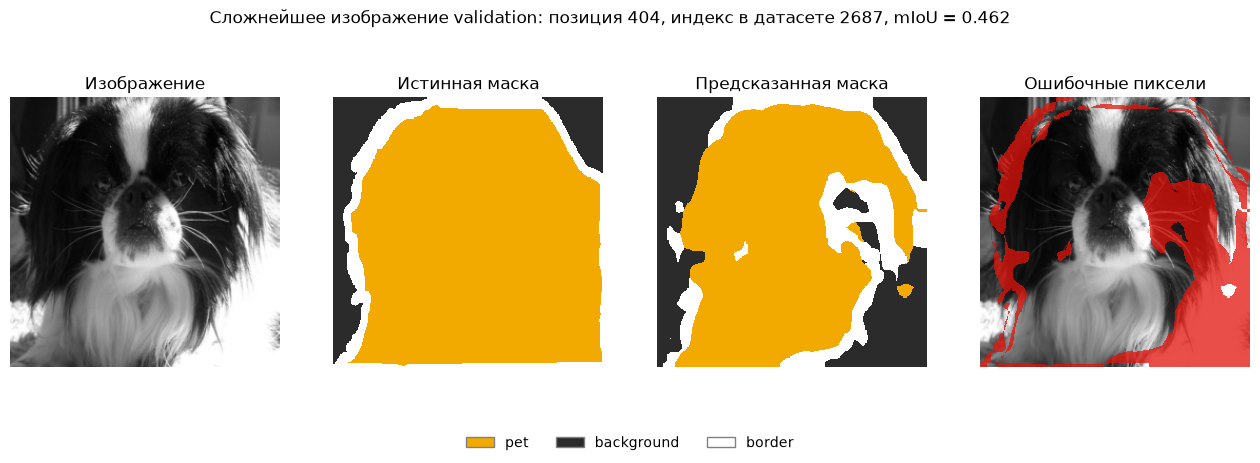

{'model': 'baseline (segmentation.pt)', 'val_position': 404, 'dataset_index': 2687, 'miou': 0.4619, 'wrong_pixel_share': 0.2681, 'wrong_pixels_on_true_border_share': 0.2057, 'median_image_miou_val': 0.7844, 'image': 'bonus_hard_case.png'}
{'iou_per_class': {'pet': 0.7211, 'background': 0.4337, 'border': 0.231}}
✔ выбрано изображение с наименьшим IoU на всём validation
✔ bonus_hard_case.png и bonus_hard_case.json сохранены


In [22]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# mIoU по трём классам для каждого изображения validation (исходная модель); сложнейшее — с наименьшим значением.
bonus_ious = []
model.eval()
with torch.no_grad():
    for x, y in val_loader:
        pred = model(x.to(DEVICE))["out"].argmax(dim=1).cpu()
        bonus_ious += [mean_iou(p, t) for p, t in zip(pred, y)]
hard_pos = int(np.argmin(bonus_ious))

x, m = val_ds[hard_pos]
y = normalize_mask(m)
with torch.no_grad():
    pred = model(x[None].to(DEVICE))["out"].argmax(dim=1)[0].cpu()
rgb = (x * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
wrong = pred != y

# Реальная RGB-картинка, истинная и предсказанная маски, карта ошибок — в одном файле для визуального разбора.
class_colors = ["#f2a900", "#2b2b2b", "#ffffff"]  # pet, background, border
cmap = ListedColormap(class_colors)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
axes[0].imshow(rgb)
axes[0].set_title("Изображение")
axes[1].imshow(y.numpy(), cmap=cmap, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
axes[1].set_title("Истинная маска")
axes[2].imshow(pred.numpy(), cmap=cmap, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
axes[2].set_title("Предсказанная маска")
axes[3].imshow(rgb)
axes[3].imshow(np.ma.masked_where(~wrong.numpy(), wrong.numpy()), cmap=ListedColormap(["#e3120b"]), alpha=0.75, interpolation="nearest")
axes[3].set_title("Ошибочные пиксели")
for ax in axes:
    ax.axis("off")
fig.legend(handles=[Patch(facecolor=c, edgecolor="gray", label=n) for c, n in zip(class_colors, CLASS_NAMES)],
           loc="lower center", ncol=NUM_CLASSES, frameon=False)
fig.suptitle(f"Сложнейшее изображение validation: позиция {hard_pos}, индекс в датасете {val_idx[hard_pos]}, mIoU = {bonus_ious[hard_pos]:.3f}")
fig.savefig(ARTIFACTS / "bonus_hard_case.png", dpi=150, bbox_inches="tight")
plt.show()

bonus_hard_case = {
    "model": "baseline (segmentation.pt)",
    "val_position": hard_pos,
    "dataset_index": val_idx[hard_pos],
    "miou": bonus_ious[hard_pos],
    "iou_per_class": {name: (((pred == c) & (y == c)).sum().item() / max(((pred == c) | (y == c)).sum().item(), 1))
                      for c, name in enumerate(CLASS_NAMES)},
    "wrong_pixel_share": wrong.float().mean().item(),
    "wrong_pixels_on_true_border_share": (wrong & (y == 2)).sum().item() / max(wrong.sum().item(), 1),
    "median_image_miou_val": float(np.median(bonus_ious)),
    "image": "bonus_hard_case.png",
}
(ARTIFACTS / "bonus_hard_case.json").write_text(json.dumps(bonus_hard_case, ensure_ascii=False, indent=2), encoding="utf-8")

print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in bonus_hard_case.items() if k != "iou_per_class"})
print({"iou_per_class": {k: round(v, 4) for k, v in bonus_hard_case["iou_per_class"].items()}})
check(len(bonus_ious) == len(val_ds) and bonus_ious[hard_pos] == min(bonus_ious), "выбрано изображение с наименьшим IoU на всём validation")
check((ARTIFACTS / "bonus_hard_case.png").exists() and (ARTIFACTS / "bonus_hard_case.json").exists(), "bonus_hard_case.png и bonus_hard_case.json сохранены")


## Анализ результатов

Все числа ниже получены в полном режиме (`FAST_DEV_RUN=False`) на реальных данных Oxford-IIIT Pet и взяты из файлов в `artifacts/lab2`.

### Бюджет

| Параметр | Значение |
|---|---|
| Модель | LRASPP-MobileNetV3-Large, 3,22 млн параметров, предобученные веса, обучается вся сеть |
| Данные | train — 3128 изображений, validation — 552, test — 3669; размер 256×256 |
| Обучение | 6 эпох (582 шага), AdamW, lr 5e-4, weight decay 1e-4, батч 32, mixed precision |
| Время | около 22 с на эпоху на GPU, 2–3 минуты на модель |
| Запуски | по одному на модель, seed 42 |

Вторая модель обучена при том же бюджете; единственное отличие — синхронное горизонтальное отражение с вероятностью 0,5.

### Отложенная оценка на test

| Показатель | Исходная, validation | Исходная, test | С отражением, validation | С отражением, test |
|---|---|---|---|---|
| mIoU | 0,7835 | 0,7860 | 0,7776 | 0,7821 |
| IoU «питомец» | 0,8776 | 0,8728 | 0,8737 | 0,8680 |
| IoU «фон» | 0,9379 | 0,9331 | 0,9323 | 0,9292 |
| IoU «граница» | 0,5349 | 0,5521 | 0,5268 | 0,5492 |
| Доля верных пикселей | 0,9285 | 0,9261 | — | 0,9240 |

Test mIoU отличается от validation на 0,003–0,005, то есть оценка на validation не была завышена: гиперпараметры по validation не подбирались, и модель одинаково работает на данных, которых не видела.

### Влияние отражения

Модель с отражением уступает исходной на validation на 0,0059 mIoU и на test на 0,0039. На validation ниже все три класса: «питомец» на 0,0039, «фон» на 0,0056, «граница» на 0,0081. Ни один класс от отражения не выиграл.

Разница составляет доли процента и получена на одном запуске каждой модели, поэтому она сопоставима со случайным разбросом обучения. Обоснованный вывод — «при этом бюджете отражение не дало улучшения», а не «отражение вредит». Правдоподобное объяснение: за 6 эпох модель не успевает переобучиться (loss на train у исходной модели всё ещё снижается: 0,153 → 0,141 на последней эпохе), а аугментация усложняет обучающую задачу — итоговый loss у второй модели выше (0,153 против 0,141).

По правилу «больший validation mIoU» выбрана исходная модель; test в выборе не участвовал.

### Ошибки модели

**Класс «граница» — главный источник ошибок.** Его IoU 0,53 при 0,88 у питомца и 0,94 у фона. По матрице ошибок validation верно распознаны 67 % пикселей границы; остальные почти поровну отнесены к питомцу и к фону. Граница — полоска шириной в несколько пикселей, и сдвиг предсказанного контура на один-два пикселя уже заметно уменьшает пересечение.

**Питомец путается с границей, а не с фоном.** Из 800 555 ложноположительных пикселей класса «питомец» 87 % по разметке относятся к границе, из 626 133 пропущенных 84 % модель отнесла к границе. Прямая путаница питомца с фоном составляет около 0,6 % пикселей validation.

**Ложноположительные ошибки преобладают.** Их на 28 % больше, чем пропусков, и они доминируют на 316 изображениях из 552: модель чаще расширяет маску питомца, чем теряет его части.

**Малые объекты сегментируются хуже.** На 139 изображениях validation, где питомец занимает не более 17,7 % кадра (нижняя четверть train), IoU питомца равен 0,805 против 0,878 по всему validation. У модели с отражением разрыв такой же (0,803 против 0,874), то есть аугментация малым объектам не помогла.

**Сложнейшие изображения.** Из восьми изображений с наименьшим IoU питомца шесть относятся к малым объектам, и на семи преобладают ложноположительные ошибки. В худшем случае (индекс 2822, IoU 0,27) питомец занимает 5 % кадра, а ложноположительных пикселей в 2,6 раза больше, чем его площадь. На `error_analysis_hardest.png` видны два типа сбоя: модель отмечает как питомца посторонние объекты (на одном из снимков — часть лица человека рядом с собакой) и закрашивает как питомца области внутри животного, которые в разметке отнесены к «границе».

**Сбой на уровне области.** Изображение с наименьшим трёхклассовым mIoU (индекс 2687, mIoU 0,46 при медиане 0,78) — чёрно-белая фотография собаки крупным планом. Модель отнесла к фону большую часть правой стороны животного: ошибочны 27 % пикселей, и только пятая часть из них приходится на истинную границу. Это не погрешность контура, а потеря целой области; вероятные причины — отсутствие цвета и объект, занимающий почти весь кадр.

### Ограничения

- **Один запуск на модель.** Разброс между запусками не измерен, поэтому различия в тысячные доли mIoU нельзя считать значимыми.
- **Короткое обучение.** 6 эпох с постоянным шагом; loss на train продолжал снижаться, так что модели не сошлись, и пользу от аугментации при длительном обучении этот эксперимент не оценивает.
- **Порядок батчей у двух моделей не совпадает**, что добавляет к сравнению ещё один источник случайности.
- **Одна аугментация и одно разрешение.** Проверено только горизонтальное отражение при 256 px; на точности тонкой границы низкое разрешение сказывается сильнее всего.
- **Анализ ошибок по изображениям сделан только для исходной модели** и только для класса «питомец».
- **Smoke-режим** (`FAST_DEV_RUN=True`) использует синтетические эллипсы и модель без предобученных весов; его показатели проверяют только исполнимость кода и в отчёт не входят.


## Выводы

1. **Компактный сегментатор решает задачу за несколько минут обучения.** LRASPP-MobileNetV3 с заменёнными головами после 6 эпох дообучения достигает mIoU 0,786 и 92,6 % верных пикселей на 3669 изображениях test (`test_metrics.json`). До обучения mIoU был на уровне случайного — 0,19.

2. **Оценка на validation оказалась надёжной.** Test mIoU (0,786) практически совпал с validation (0,783), так что решения, принятые по validation, не привели к подгонке (`val_metrics.json`, `test_metrics.json`).

3. **Синхронное горизонтальное отражение не улучшило качество при том же бюджете.** Модель с отражением ниже на 0,006 mIoU на validation и на 0,004 на test, причём по всем трём классам (`augmentation_comparison.json`, `class_deltas.json`). Разница лежит в пределах разброса одного запуска, поэтому итог — отсутствие выигрыша, а не доказанный вред. Для дальнейшей работы выбрана исходная модель; выбор сделан по validation.

4. **Качество ограничивает класс «граница», а не различение питомца и фона.** IoU границы 0,53–0,55 против 0,87 у питомца и 0,93 у фона; 84–87 % ошибок класса «питомец» — это путаница с границей (`val_metrics.json`). Средний mIoU занижен именно этим классом, а доля верных пикселей его почти не отражает.

5. **Малые объекты — устойчивое слабое место.** На нижней четверти объектов по площади IoU питомца падает с 0,878 до 0,805, и отражение этот разрыв не сокращает (`small_objects.json`). Шесть из восьми самых сложных изображений validation — малые объекты (`error_analysis.json`).

6. **Модель склонна расширять маску питомца.** Ложноположительных пикселей на 28 % больше, чем пропущенных, и на сложнейших изображениях маска захватывает посторонние объекты (`error_analysis.json`, `error_analysis_hardest.png`). Отдельный тип сбоя — потеря целой области объекта на нетипичном снимке (`bonus_hard_case.png`).

**Что стоит проверить дальше.** Повторить оба обучения с несколькими seed, чтобы оценить разброс; обучать дольше и с убывающим шагом, чтобы проверить аугментацию в режиме, где возможно переобучение; повысить разрешение или изменить вес класса «граница» в функции потерь, поскольку именно он определяет потолок mIoU.
